In [ ]:
!pip -q install -U transformers accelerate pillow matplotlib requests


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.34.2 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [ ]:
%pip install -q "requests==2.32.4" "pillow>=10,<13" transformers accelerate matplotlib pandas

In [ ]:
import requests
import PIL
import transformers
import torch

print("Requests:", requests.__version__)
print("Pillow:", PIL.__version__)
print("Transformers:", transformers.__version__)
print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.is_available())


Requests: 2.32.4
Pillow: 12.3.0
Transformers: 5.22.1
PyTorch: 2.11.0+cpu
GPU: False


In [ ]:
import torch

print("GPU:", torch.cuda.is_available())
print("PyTorch:", torch.__version__)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))


GPU: True
PyTorch: 2.11.0+cu130
GPU Name: Tesla T4


In [ ]:
import torch
from transformers import Owlv2Processor, Owlv2ForObjectDetection

device = "cuda" if torch.cuda.is_available() else "cpu"

model_id = "google/owlv2-base-patch16"

processor = Owlv2Processor.from_pretrained(model_id)
model = Owlv2ForObjectDetection.from_pretrained(model_id)

model = model.to(device)
model.eval()

print("Model başarıyla yüklendi!")
print("Kullanılan cihaz:", device)

preprocessor_config.json:   0%|          | 0.00/425 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/1.10k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.06M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/67.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/121 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  620MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/418 [00:00<?, ?it/s]

Model başarıyla yüklendi!
Kullanılan cihaz: cuda


In [ ]:
%pip install -q datasets

In [ ]:
from datasets import load_dataset

dataset = load_dataset(
    "finedet/coco2017",
    split="validation",
    streaming=True
)

samples = list(dataset.take(20))

print("Yüklenen görüntü sayısı:", len(samples))
print("Veri alanları:", samples[0].keys())

README.md:   0%|          | 0.00/5.12k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/48 [00:00<?, ?it/s]

Yüklenen görüntü sayısı: 20
Veri alanları: dict_keys(['image', 'width', 'height', 'objects'])


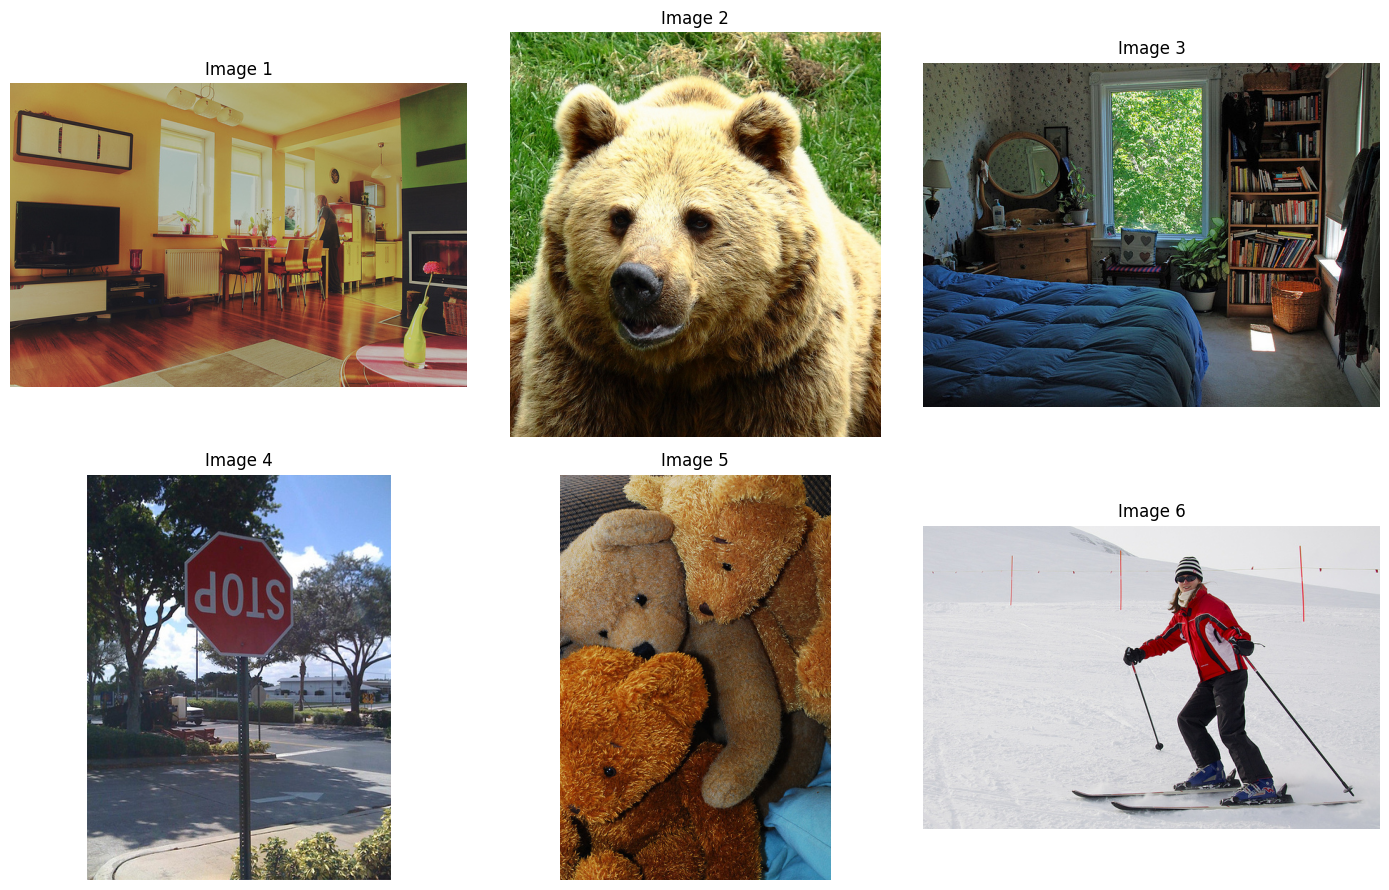

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i]["image"])
    ax.set_title(f"Image {i+1}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
# Datasetten ilk görüntüyü seç
image = samples[0]["image"].convert("RGB")

# Modelin aramasını istediğimiz nesneler
texts = [[
    "a television",
    "a chair",
    "a dining table",
    "a person",
    "a potted plant",
    "a couch"
]]

# Görüntü ve metinleri modele hazırla
inputs = processor(
    text=texts,
    images=image,
    return_tensors="pt"
).to(device)

# Model tahmini
with torch.no_grad():
    outputs = model(**inputs)

# Bounding box sonuçları
target_sizes = torch.tensor([
    (image.height, image.width)
])

results = processor.post_process_grounded_object_detection(
    outputs=outputs,
    target_sizes=target_sizes,
    threshold=0.1,
    text_labels=texts
)[0]

print("Tespit edilen nesne sayısı:", len(results["boxes"]))

Tespit edilen nesne sayısı: 26


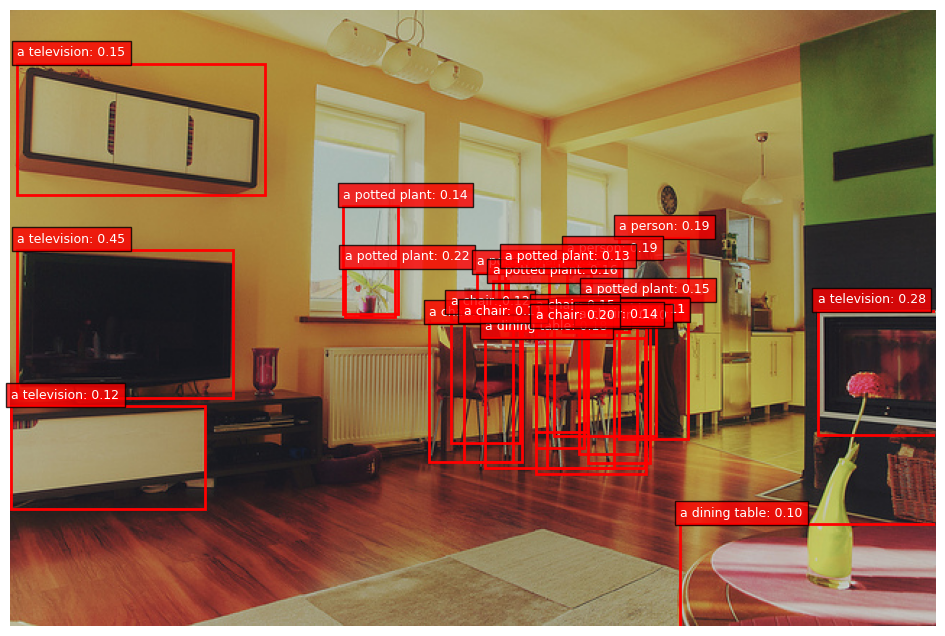

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

for box, score, label in zip(
    results["boxes"],
    results["scores"],
    results["text_labels"]
):
    x1, y1, x2, y2 = box.tolist()

    rect = Rectangle(
        (x1, y1),
        x2-x1,
        y2-y1,
        fill=False,
        edgecolor="red",
        linewidth=2
    )
    ax.add_patch(rect)

    ax.text(
        x1, max(y1-5, 0),
        f"{label}: {score.item():.2f}",
        color="white",
        fontsize=9,
        bbox=dict(facecolor="red", alpha=0.8)
    )

plt.axis("off")
plt.show()

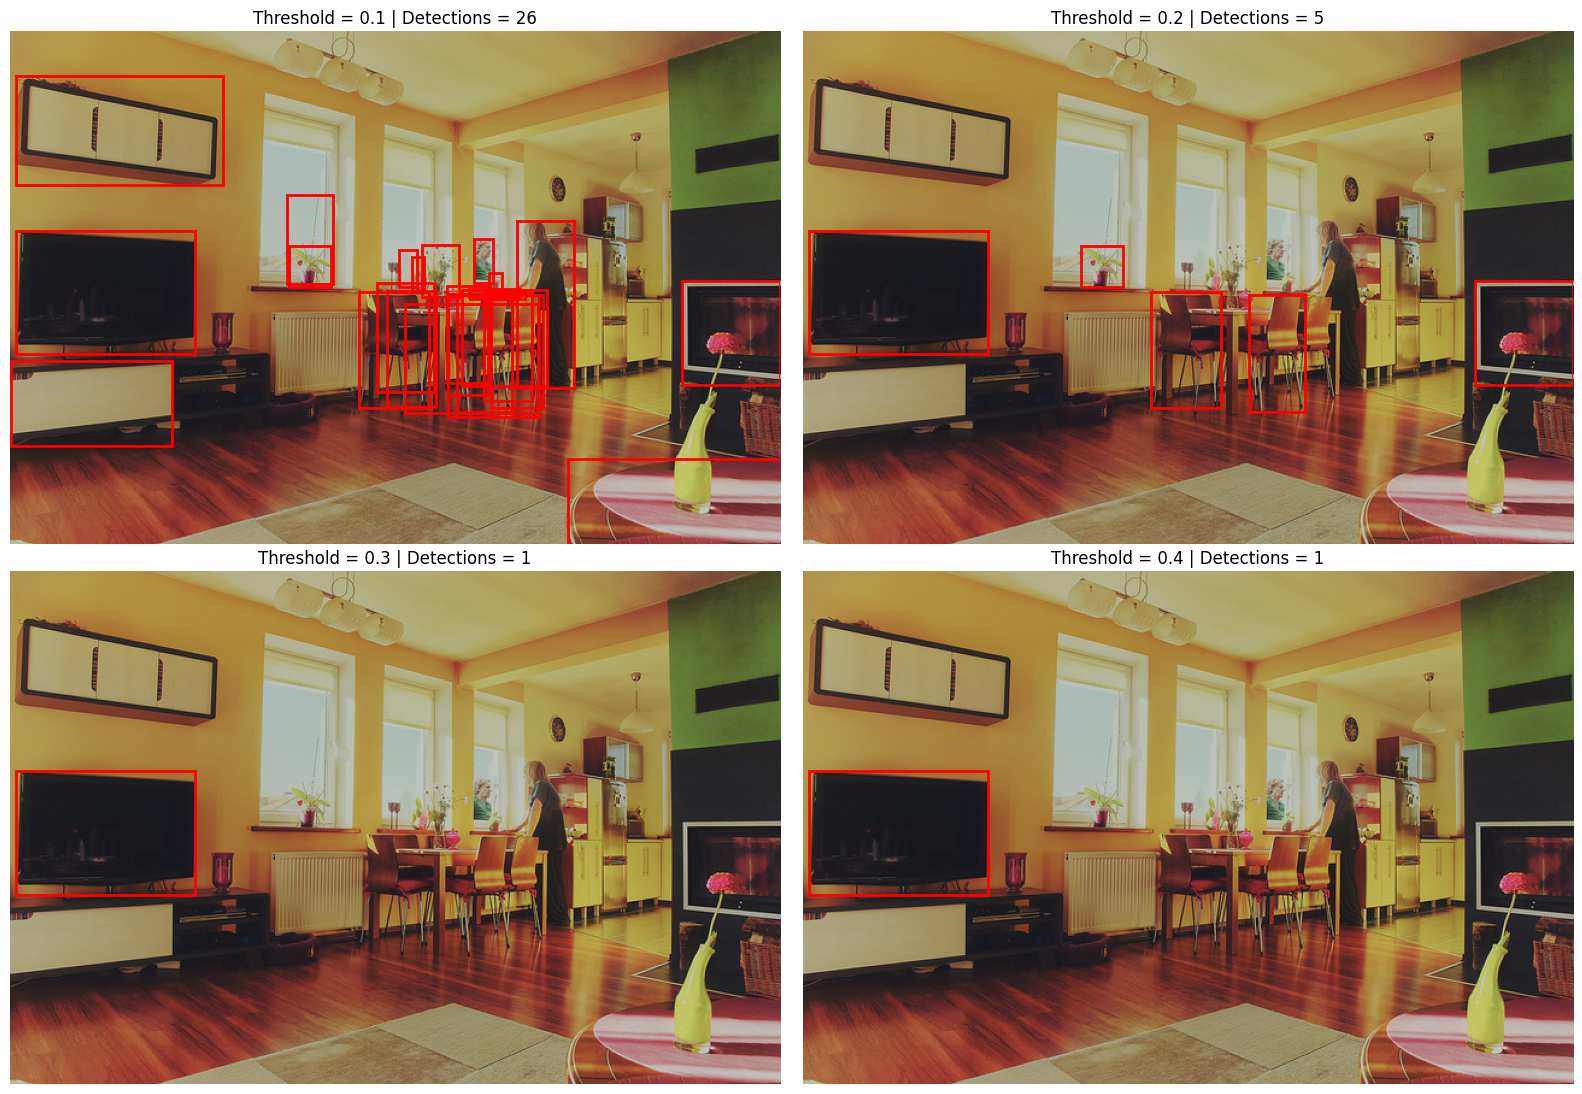

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

thresholds = [0.1, 0.2, 0.3, 0.4]

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for ax, threshold in zip(axes.flat, thresholds):

    ax.imshow(image)
    count = 0

    for box, score, label in zip(
        results["boxes"],
        results["scores"],
        results["text_labels"]
    ):
        if score.item() < threshold:
            continue

        x1, y1, x2, y2 = box.tolist()

        rect = Rectangle(
            (x1, y1),
            x2-x1,
            y2-y1,
            fill=False,
            edgecolor="red",
            linewidth=2
        )

        ax.add_patch(rect)
        count += 1

    ax.set_title(
        f"Threshold = {threshold} | Detections = {count}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

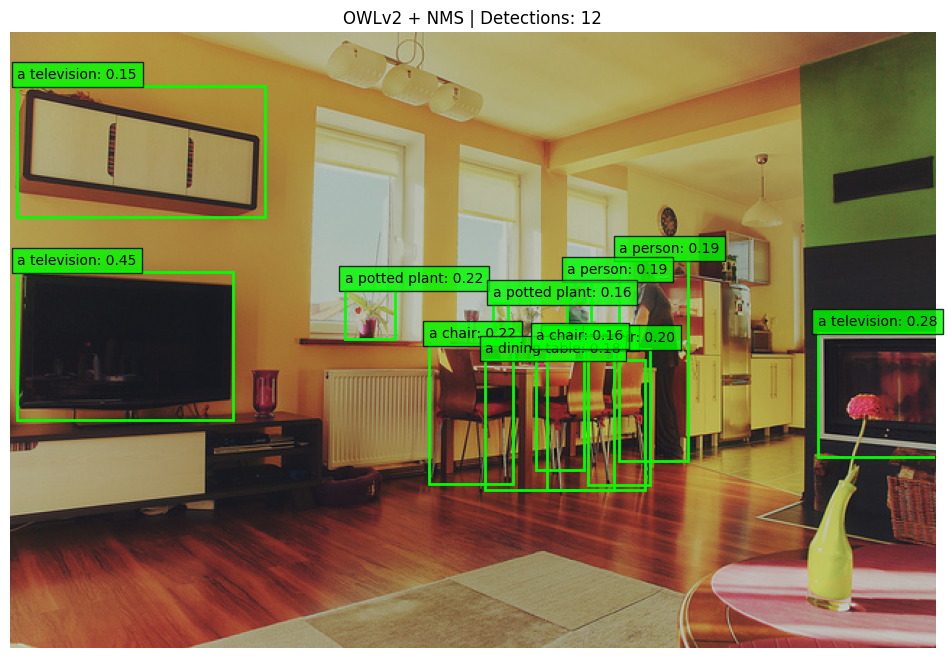

NMS öncesi: 14
NMS sonrası: 12


In [ ]:
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from torchvision.ops import batched_nms

boxes = results["boxes"].detach().cpu()
scores = results["scores"].detach().cpu()
labels = results["labels"].detach().cpu()

# Önce düşük skorlu tahminleri filtrele
mask = scores >= 0.15

boxes = boxes[mask]
scores = scores[mask]
labels = labels[mask]

# Aynı sınıftaki örtüşen kutulara NMS uygula
keep = batched_nms(
    boxes,
    scores,
    labels,
    iou_threshold=0.5
)

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

for i in keep.tolist():
    x1, y1, x2, y2 = boxes[i].tolist()

    rect = Rectangle(
        (x1, y1),
        x2-x1,
        y2-y1,
        fill=False,
        edgecolor="lime",
        linewidth=2
    )
    ax.add_patch(rect)

    ax.text(
        x1, max(y1-5, 0),
        f"{texts[0][labels[i].item()]}: {scores[i].item():.2f}",
        color="black",
        bbox=dict(facecolor="lime", alpha=0.8)
    )

ax.set_title(f"OWLv2 + NMS | Detections: {len(keep)}")
ax.axis("off")
plt.show()

print("NMS öncesi:", len(boxes))
print("NMS sonrası:", len(keep))

In [ ]:
from tqdm.auto import tqdm
import pandas as pd
import torch

# COCO 80 sınıf
coco_classes = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench",
    "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite",
    "baseball bat", "baseball glove", "skateboard",
    "surfboard", "tennis racket", "bottle", "wine glass",
    "cup", "fork", "knife", "spoon", "bowl", "banana",
    "apple", "sandwich", "orange", "broccoli", "carrot",
    "hot dog", "pizza", "donut", "cake", "chair",
    "couch", "potted plant", "bed", "dining table",
    "toilet", "tv", "laptop", "mouse", "remote",
    "keyboard", "cell phone", "microwave", "oven",
    "toaster", "sink", "refrigerator", "book", "clock",
    "vase", "scissors", "teddy bear", "hair drier",
    "toothbrush"
]

queries = [[f"a photo of a {name}" for name in coco_classes]]

all_predictions = []
image_results = []

for image_id, sample in enumerate(tqdm(samples)):

    img = sample["image"].convert("RGB")

    inputs = processor(
        text=queries,
        images=img,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    result = processor.post_process_object_detection(
        outputs=outputs,
        target_sizes=torch.tensor([(img.height, img.width)]),
        threshold=0.2
    )[0]

    image_results.append(result)

    for box, score, label in zip(
        result["boxes"],
        result["scores"],
        result["labels"]
    ):
        all_predictions.append({
            "image_id": image_id,
            "class": coco_classes[label.item()],
            "confidence": score.item(),
            "box": box.tolist()
        })

df_predictions = pd.DataFrame(all_predictions)

print("İşlenen görüntü:", len(samples))
print("Toplam tespit:", len(df_predictions))

display(df_predictions.head(10))

  0%|          | 0/20 [00:00<?, ?it/s]

AttributeError: 'Owlv2Processor' object has no attribute 'post_process_object_detection'

In [ ]:
import torch
import pandas as pd
from tqdm.auto import tqdm
from torchvision.ops import batched_nms

# COCO veri kümesindeki 80 nesne sınıfı
coco_classes = [
    "person", "bicycle", "car", "motorcycle", "airplane",
    "bus", "train", "truck", "boat", "traffic light",
    "fire hydrant", "stop sign", "parking meter", "bench",
    "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack",
    "umbrella", "handbag", "tie", "suitcase", "frisbee",
    "skis", "snowboard", "sports ball", "kite",
    "baseball bat", "baseball glove", "skateboard",
    "surfboard", "tennis racket", "bottle", "wine glass",
    "cup", "fork", "knife", "spoon", "bowl", "banana",
    "apple", "sandwich", "orange", "broccoli", "carrot",
    "hot dog", "pizza", "donut", "cake", "chair",
    "couch", "potted plant", "bed", "dining table",
    "toilet", "tv", "laptop", "mouse", "remote",
    "keyboard", "cell phone", "microwave", "oven",
    "toaster", "sink", "refrigerator", "book", "clock",
    "vase", "scissors", "teddy bear", "hair drier",
    "toothbrush"
]

# OWLv2 için metin sorguları
queries = [[f"a photo of a {name}" for name in coco_classes]]

all_predictions = []
image_results = []

# Modelin GPU veya CPU üzerinde olduğundan emin ol
device = "cuda" if torch.cuda.is_available() else "cpu"
model = model.to(device)
model.eval()

# 20 görüntüyü sırayla analiz et
for image_id, sample in enumerate(tqdm(samples)):

    img = sample["image"].convert("RGB")

    # Görüntü ve metinleri hazırla
    inputs = processor(
        text=queries,
        images=img,
        return_tensors="pt"
    ).to(device)

    # OWLv2 tahmini
    with torch.no_grad():
        outputs = model(**inputs)

    # Bounding box sonuçlarını elde et
    result = processor.post_process_grounded_object_detection(
        outputs=outputs,
        target_sizes=torch.tensor([(img.height, img.width)]),
        threshold=0.2,
        text_labels=queries
    )[0]

    # NMS ile tekrar eden kutuları azalt
    boxes = result["boxes"].detach().cpu()
    scores = result["scores"].detach().cpu()
    labels = result["labels"].detach().cpu()

    if len(boxes) > 0:
        keep = batched_nms(
            boxes,
            scores,
            labels,
            iou_threshold=0.5
        )

        boxes = boxes[keep]
        scores = scores[keep]
        labels = labels[keep]

    # Sonuçları kaydet
    image_results.append({
        "image_id": image_id,
        "boxes": boxes,
        "scores": scores,
        "labels": labels
    })

    for box, score, label in zip(boxes, scores, labels):
        all_predictions.append({
            "image_id": image_id,
            "class": coco_classes[label.item()],
            "confidence": round(score.item(), 4),
            "box": box.tolist()
        })

# DataFrame oluştur
df_predictions = pd.DataFrame(
    all_predictions,
    columns=["image_id", "class", "confidence", "box"]
)

print("İşlenen görüntü sayısı:", len(samples))
print("Toplam tespit sayısı:", len(df_predictions))

display(df_predictions.head(10))

  0%|          | 0/20 [00:00<?, ?it/s]

İşlenen görüntü sayısı: 20
Toplam tespit sayısı: 61


,image_id,class,confidence,box
0,0,tv,0.4918,"[4.62338924407959, 165.59007263183594, 153.529..."
1,0,clock,0.3438,"[448.564208984375, 120.48260498046875, 461.797..."
2,0,vase,0.3410,"[548.979736328125, 309.0632629394531, 585.4723..."
3,0,tv,0.2792,"[558.1404418945312, 207.31973266601562, 639.75..."
4,0,vase,0.2193,"[338.58319091796875, 200.43008422851562, 347.2..."
5,0,vase,0.2033,"[351.9510192871094, 208.29542541503906, 362.03..."
6,1,bear,0.5973,"[7.6175689697265625, 66.262451171875, 586.5857..."
7,2,bed,0.2892,"[-0.03631591796875, 286.79315185546875, 352.02..."
8,2,potted plant,0.2394,"[363.5269470214844, 212.95164489746094, 440.03..."
9,2,chair,0.2308,"[250.44406127929688, 235.1739501953125, 328.73..."


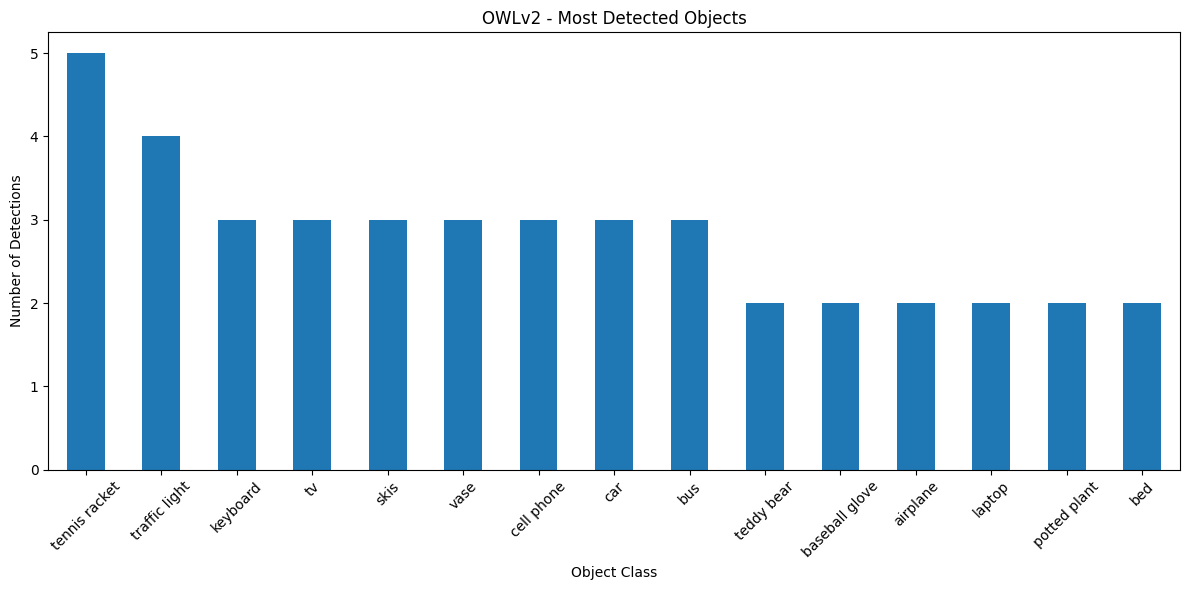

In [ ]:
import matplotlib.pyplot as plt

class_counts = df_predictions["class"].value_counts()

plt.figure(figsize=(12, 6))
class_counts.head(15).plot(kind="bar")

plt.title("OWLv2 - Most Detected Objects")
plt.xlabel("Object Class")
plt.ylabel("Number of Detections")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

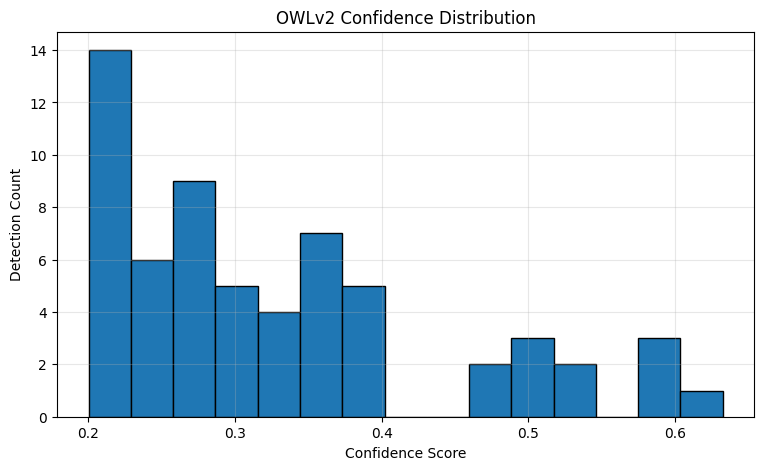

In [ ]:
plt.figure(figsize=(9, 5))

plt.hist(
    df_predictions["confidence"],
    bins=15,
    edgecolor="black"
)

plt.title("OWLv2 Confidence Distribution")
plt.xlabel("Confidence Score")
plt.ylabel("Detection Count")
plt.grid(alpha=0.3)
plt.show()


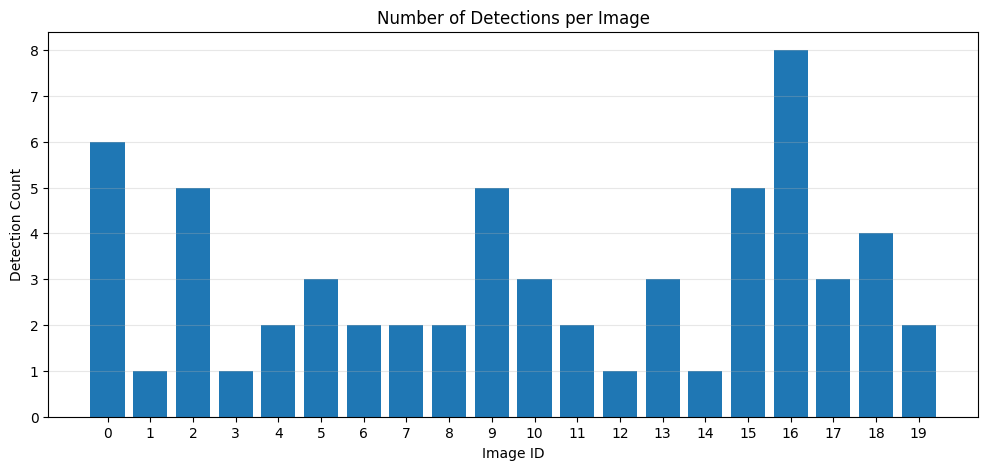

Ortalama tespit sayısı: 3.05


In [ ]:
detections_per_image = (
    df_predictions.groupby("image_id")
    .size()
    .reindex(range(len(samples)), fill_value=0)
)

plt.figure(figsize=(12, 5))
plt.bar(
    detections_per_image.index,
    detections_per_image.values
)

plt.title("Number of Detections per Image")
plt.xlabel("Image ID")
plt.ylabel("Detection Count")
plt.xticks(range(len(samples)))
plt.grid(axis="y", alpha=0.3)
plt.show()

print(
    "Ortalama tespit sayısı:",
    round(detections_per_image.mean(), 2)
)

In [ ]:
# Datasetin yapısını incele
print("DATASET ALANLARI:")
print(samples[0].keys())

print("\nİLK ÖRNEĞİN BİLGİLERİ:")

for key, value in samples[0].items():

    if key == "image":
        print(
            key,
            ":",
            type(value),
            value.size
        )
    else:
        print(
            key,
            ":",
            str(value)[:1500]
        )

DATASET ALANLARI:
dict_keys(['image', 'width', 'height', 'objects'])

İLK ÖRNEĞİN BİLGİLERİ:
image : <class 'PIL.JpegImagePlugin.JpegImageFile'> (640, 426)
width : 640
height : 426
objects : {'bbox': [[236.97999572753906, 142.50999450683594, 24.700000762939453, 69.5], [7.03000020980835, 167.75999450683594, 149.32000732421875, 94.87000274658203], [557.2100219726562, 209.19000244140625, 81.3499984741211, 78.7300033569336], [358.9800109863281, 218.0500030517578, 56.0, 102.83000183105469], [290.69000244140625, 218.0, 61.83000183105469, 98.4800033569336], [413.20001220703125, 223.00999450683594, 30.170000076293945, 81.36000061035156], [317.3999938964844, 219.24000549316406, 21.579999923706055, 11.59000015258789], [412.79998779296875, 157.61000061035156, 53.04999923706055, 138.00999450683594], [384.42999267578125, 172.2100067138672, 15.119999885559082, 35.7400016784668], [512.219970703125, 205.75, 14.739999771118164, 15.970000267028809], [493.1000061035156, 174.33999633789062, 20.29000091552

In [ ]:
objects = samples[0]["objects"]

print("OBJECTS ALANLARI:")
print(objects.keys())

print("\nİLK 5 NESNENİN BİLGİLERİ:")

for key, value in objects.items():
    print(f"{key}: {str(value[:5])[:500]}")

OBJECTS ALANLARI:
dict_keys(['bbox', 'category'])

İLK 5 NESNENİN BİLGİLERİ:
bbox: [[236.97999572753906, 142.50999450683594, 24.700000762939453, 69.5], [7.03000020980835, 167.75999450683594, 149.32000732421875, 94.87000274658203], [557.2100219726562, 209.19000244140625, 81.3499984741211, 78.7300033569336], [358.9800109863281, 218.0500030517578, 56.0, 102.83000183105469], [290.69000244140625, 218.0, 61.83000183105469, 98.4800033569336]]
category: [58, 62, 62, 56, 56]


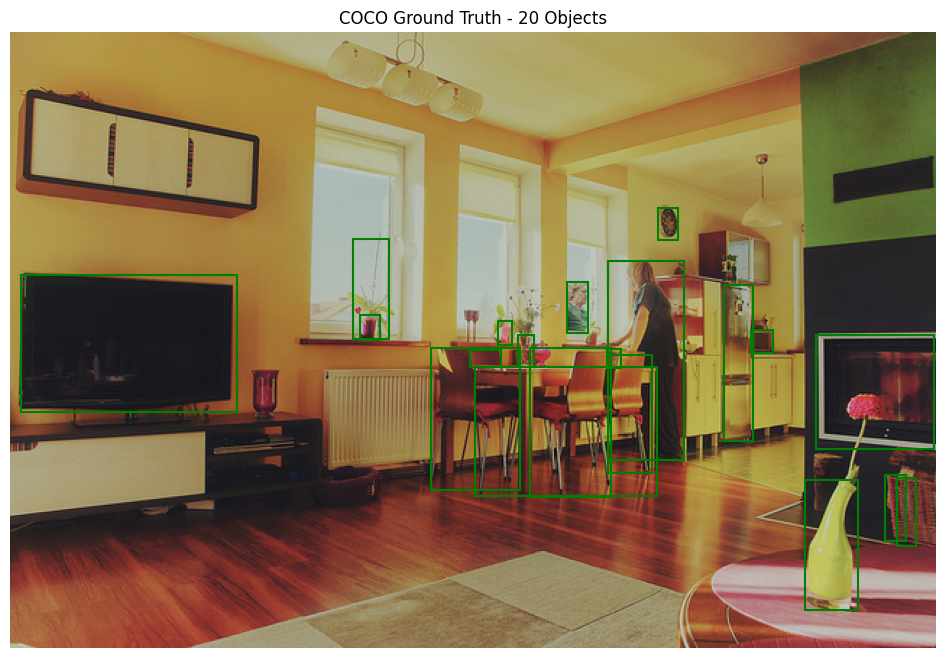

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

sample = samples[0]
image = sample["image"].convert("RGB")
gt_boxes = sample["objects"]["bbox"]

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(image)

for box in gt_boxes:
    x, y, w, h = box

    rect = Rectangle(
        (x, y),
        w,
        h,
        fill=False,
        edgecolor="green",
        linewidth=1.5
    )

    ax.add_patch(rect)

ax.set_title(
    f"COCO Ground Truth - {len(gt_boxes)} Objects"
)
ax.axis("off")
plt.show()

In [ ]:
# Datasetin kategori özelliklerini incele

print("CATEGORY FEATURE:")
print(dataset.features["objects"])

print("\nİLK GÖRÜNTÜDEKİ CATEGORY ID'LER:")

category_ids = samples[0]["objects"]["category"]

print(sorted(set(category_ids)))

print("\nİLK 5 CATEGORY:")
print(category_ids[:5])

CATEGORY FEATURE:
{'bbox': List(List(Value('float32'), length=4)), 'category': List(ClassLabel(names=['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow', 'elephant', 'bear', 'zebra', 'giraffe', 'backpack', 'umbrella', 'handbag', 'tie', 'suitcase', 'frisbee', 'skis', 'snowboard', 'sports ball', 'kite', 'baseball bat', 'baseball glove', 'skateboard', 'surfboard', 'tennis racket', 'bottle', 'wine glass', 'cup', 'fork', 'knife', 'spoon', 'bowl', 'banana', 'apple', 'sandwich', 'orange', 'broccoli', 'carrot', 'hot dog', 'pizza', 'donut', 'cake', 'chair', 'couch', 'potted plant', 'bed', 'dining table', 'toilet', 'tv', 'laptop', 'mouse', 'remote', 'keyboard', 'cell phone', 'microwave', 'oven', 'toaster', 'sink', 'refrigerator', 'book', 'clock', 'vase', 'scissors', 'teddy bear', 'hair drier', 'toothbrush']))}

İLK GÖRÜNTÜDEKİ CATEGORY ID'LER:


In [ ]:
import numpy as np
import pandas as pd
from torchvision.ops import box_iou

# Dataset sınıf isimlerini doğrudan al
gt_classes = dataset.features["objects"]["category"].feature.names

assert gt_classes == coco_classes, "Sınıf sıralamaları eşleşmiyor!"
assert len(samples) == len(image_results)

TP = 0
FP = 0
FN = 0

per_image_results = []

IOU_THRESHOLD = 0.50

for image_id, sample in enumerate(samples):

    # Ground Truth
    gt_boxes_xywh = sample["objects"]["bbox"]
    gt_labels = sample["objects"]["category"]

    # COCO xywh -> xyxy dönüşümü
    gt_boxes = []

    for x, y, w, h in gt_boxes_xywh:
        gt_boxes.append([x, y, x + w, y + h])

    gt_boxes = torch.tensor(
        gt_boxes, dtype=torch.float32
    ).reshape(-1, 4)

    gt_labels = torch.tensor(gt_labels, dtype=torch.long)

    # OWLv2 tahminleri
    pred = image_results[image_id]

    pred_boxes = pred["boxes"].cpu().float()
    pred_scores = pred["scores"].cpu().float()
    pred_labels = pred["labels"].cpu().long()

    # Yüksek skorlu tahminleri önce değerlendir
    order = torch.argsort(pred_scores, descending=True)

    matched_gt = set()

    image_tp = 0
    image_fp = 0

    for idx in order.tolist():

        pred_box = pred_boxes[idx].unsqueeze(0)
        pred_label = pred_labels[idx]

        # Yalnızca aynı sınıftaki GT kutularıyla karşılaştır
        candidates = [
            j for j in range(len(gt_labels))
            if gt_labels[j] == pred_label
            and j not in matched_gt
        ]

        if len(candidates) == 0:
            image_fp += 1
            continue

        ious = box_iou(
            pred_box,
            gt_boxes[candidates]
        )[0]

        best_idx = torch.argmax(ious).item()
        best_iou = ious[best_idx].item()

        if best_iou >= IOU_THRESHOLD:
            image_tp += 1
            matched_gt.add(candidates[best_idx])
        else:
            image_fp += 1

    image_fn = len(gt_labels) - len(matched_gt)

    TP += image_tp
    FP += image_fp
    FN += image_fn

    per_image_results.append({
        "image_id": image_id,
        "TP": image_tp,
        "FP": image_fp,
        "FN": image_fn
    })

# Metrikler
precision = TP / (TP + FP) if TP + FP > 0 else 0
recall = TP / (TP + FN) if TP + FN > 0 else 0

f1 = (
    2 * precision * recall / (precision + recall)
    if precision + recall > 0 else 0
)

print("===== OWLv2 PERFORMANCE =====")
print("Images:", len(samples))
print("TP:", TP)
print("FP:", FP)
print("FN:", FN)

print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")

df_metrics = pd.DataFrame(per_image_results)
display(df_metrics)

===== OWLv2 PERFORMANCE =====
Images: 20
TP: 38
FP: 23
FN: 105
Precision: 0.6230
Recall:    0.2657
F1-Score:  0.3725


,image_id,TP,FP,FN
0,0,6,0,14
1,1,1,0,0
2,2,4,1,14
3,3,1,0,3
4,4,2,0,2
5,5,1,2,1
6,6,2,0,0
7,7,1,1,3
8,8,1,1,8
9,9,1,4,16


In [ ]:
import torch
from tqdm.auto import tqdm
from torchvision.ops import batched_nms

raw_results = []

for image_id, sample in enumerate(tqdm(samples)):

    img = sample["image"].convert("RGB")

    inputs = processor(
        text=queries,
        images=img,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        outputs = model(**inputs)

    result = processor.post_process_grounded_object_detection(
        outputs=outputs,
        target_sizes=torch.tensor([(img.height, img.width)]),
        threshold=0.05,
        text_labels=queries
    )[0]

    raw_results.append({
        "boxes": result["boxes"].detach().cpu(),
        "scores": result["scores"].detach().cpu(),
        "labels": result["labels"].detach().cpu()
    })

print("20 görüntü için düşük eşikli tahminler kaydedildi.")
print(
    "Toplam ham tespit:",
    sum(len(r["boxes"]) for r in raw_results)
)

  0%|          | 0/20 [00:00<?, ?it/s]

20 görüntü için düşük eşikli tahminler kaydedildi.
Toplam ham tespit: 892


In [ ]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from torchvision.ops import box_iou, batched_nms

thresholds = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]

IOU_THRESHOLD = 0.50
NMS_THRESHOLD = 0.50

def evaluate_threshold(threshold):

    total_tp = 0
    total_fp = 0
    total_fn = 0

    for image_id, sample in enumerate(samples):

        # Ground Truth kutuları: xywh -> xyxy
        gt_xywh = sample["objects"]["bbox"]

        gt_boxes = torch.tensor(
            [
                [x, y, x + w, y + h]
                for x, y, w, h in gt_xywh
            ],
            dtype=torch.float32
        ).reshape(-1, 4)

        gt_labels = torch.tensor(
            sample["objects"]["category"],
            dtype=torch.long
        )

        # Önceden kaydedilen OWLv2 tahminleri
        pred = raw_results[image_id]

        boxes = pred["boxes"].cpu().float()
        scores = pred["scores"].cpu().float()
        labels = pred["labels"].cpu().long()

        # Confidence threshold
        mask = scores >= threshold

        boxes = boxes[mask]
        scores = scores[mask]
        labels = labels[mask]

        # NMS
        if len(boxes) > 0:
            keep = batched_nms(
                boxes,
                scores,
                labels,
                iou_threshold=NMS_THRESHOLD
            )

            boxes = boxes[keep]
            scores = scores[keep]
            labels = labels[keep]

        # Yüksek skorlu tahminleri önce eşleştir
        order = torch.argsort(scores, descending=True)

        matched_gt = set()
        image_tp = 0
        image_fp = 0

        for idx in order.tolist():

            same_class = [
                j for j in range(len(gt_labels))
                if gt_labels[j].item() == labels[idx].item()
                and j not in matched_gt
            ]

            if not same_class:
                image_fp += 1
                continue

            ious = box_iou(
                boxes[idx].unsqueeze(0),
                gt_boxes[same_class]
            )[0]

            best = torch.argmax(ious).item()

            if ious[best].item() >= IOU_THRESHOLD:
                matched_gt.add(same_class[best])
                image_tp += 1
            else:
                image_fp += 1

        image_fn = len(gt_labels) - len(matched_gt)

        total_tp += image_tp
        total_fp += image_fp
        total_fn += image_fn

    precision = (
        total_tp / (total_tp + total_fp)
        if total_tp + total_fp > 0 else 0
    )

    recall = (
        total_tp / (total_tp + total_fn)
        if total_tp + total_fn > 0 else 0
    )

    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    return {
        "Threshold": threshold,
        "TP": total_tp,
        "FP": total_fp,
        "FN": total_fn,
        "Precision": precision,
        "Recall": recall,
        "F1": f1
    }


# Tüm threshold değerlerini değerlendir
evaluation_results = []

for threshold in thresholds:
    evaluation_results.append(
        evaluate_threshold(threshold)
    )

df_thresholds = pd.DataFrame(evaluation_results)

display(df_thresholds.round(4))

best_row = df_thresholds.loc[df_thresholds["F1"].idxmax()]

print("\nEn yüksek F1 veren threshold:", best_row["Threshold"])
print("Precision:", round(best_row["Precision"], 4))
print("Recall:", round(best_row["Recall"], 4))
print("F1:", round(best_row["F1"], 4))

,Threshold,TP,FP,FN,Precision,Recall,F1
0,0.05,85,629,58,0.1190,0.5944,0.1984
1,0.10,69,197,74,0.2594,0.4825,0.3374
2,0.15,52,59,91,0.4685,0.3636,0.4094
3,0.20,38,23,105,0.6230,0.2657,0.3725
4,0.25,30,11,113,0.7317,0.2098,0.3261
5,0.30,24,6,119,0.8000,0.1678,0.2775



En yüksek F1 veren threshold: 0.15
Precision: 0.4685
Recall: 0.3636
F1: 0.4094


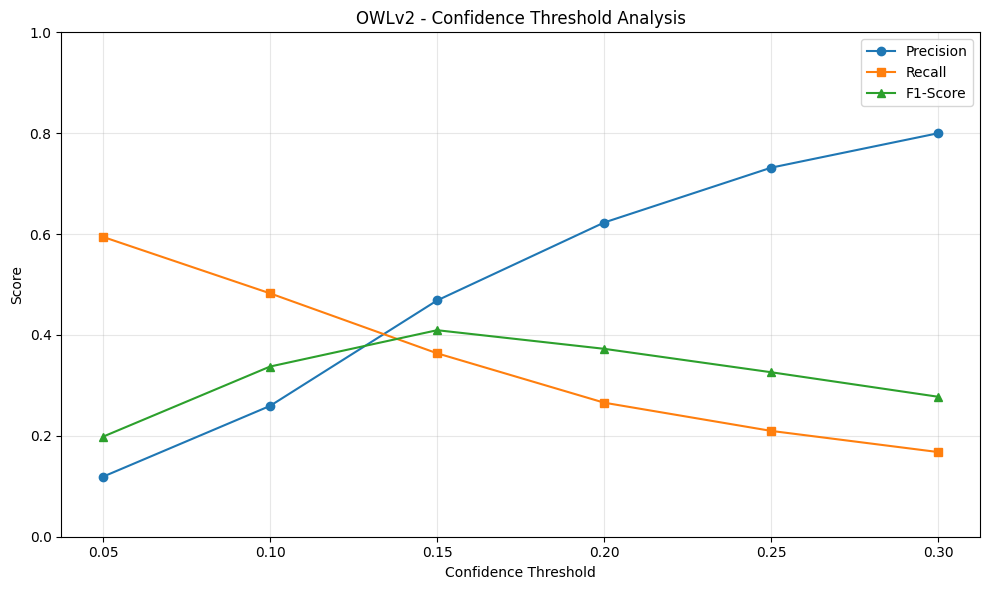

In [ ]:
plt.figure(figsize=(10, 6))

plt.plot(
    df_thresholds["Threshold"],
    df_thresholds["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    df_thresholds["Threshold"],
    df_thresholds["Recall"],
    marker="s",
    label="Recall"
)

plt.plot(
    df_thresholds["Threshold"],
    df_thresholds["F1"],
    marker="^",
    label="F1-Score"
)

plt.xlabel("Confidence Threshold")
plt.ylabel("Score")
plt.title("OWLv2 - Confidence Threshold Analysis")

plt.ylim(0, 1)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
from collections import defaultdict
import torch
import pandas as pd
from torchvision.ops import box_iou, batched_nms

THRESHOLD = 0.15
IOU_THRESHOLD = 0.50

stats = defaultdict(lambda: {"TP": 0, "FP": 0, "FN": 0})

for image_id, sample in enumerate(samples):

    gt_boxes = torch.tensor([
        [x, y, x+w, y+h]
        for x, y, w, h in sample["objects"]["bbox"]
    ], dtype=torch.float32).reshape(-1, 4)

    gt_labels = torch.tensor(
        sample["objects"]["category"], dtype=torch.long
    )

    pred = raw_results[image_id]

    mask = pred["scores"] >= THRESHOLD

    boxes = pred["boxes"][mask].cpu().float()
    scores = pred["scores"][mask].cpu().float()
    labels = pred["labels"][mask].cpu().long()

    if len(boxes) > 0:
        keep = batched_nms(boxes, scores, labels, 0.5)
        boxes, scores, labels = (
            boxes[keep], scores[keep], labels[keep]
        )

    matched_gt = set()

    for idx in torch.argsort(scores, descending=True).tolist():

        cls = labels[idx].item()

        candidates = [
            j for j in range(len(gt_labels))
            if gt_labels[j].item() == cls
            and j not in matched_gt
        ]

        if candidates:
            ious = box_iou(
                boxes[idx].unsqueeze(0),
                gt_boxes[candidates]
            )[0]

            best = torch.argmax(ious).item()

            if ious[best].item() >= IOU_THRESHOLD:
                stats[cls]["TP"] += 1
                matched_gt.add(candidates[best])
                continue

        stats[cls]["FP"] += 1

    for j, cls in enumerate(gt_labels.tolist()):
        if j not in matched_gt:
            stats[cls]["FN"] += 1

rows = []

for cls, counts in stats.items():
    tp, fp, fn = counts["TP"], counts["FP"], counts["FN"]

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall else 0
    )

    rows.append({
        "Class": coco_classes[cls],
        "GT Count": tp + fn,
        "TP": tp,
        "FP": fp,
        "FN": fn,
        "Precision": round(precision, 3),
        "Recall": round(recall, 3),
        "F1": round(f1, 3)
    })

df_class_metrics = pd.DataFrame(rows)

df_class_metrics = df_class_metrics.sort_values(
    ["GT Count", "F1"], ascending=[False, False]
)

display(df_class_metrics.head(20))

,Class,GT Count,TP,FP,FN,Precision,Recall,F1
7,person,54,4,0,50,1.000,0.074,0.138
10,book,16,0,5,16,0.000,0.000,0.000
16,car,8,4,1,4,0.800,0.500,0.615
6,chair,6,3,0,3,1.000,0.500,0.667
2,vase,4,4,4,0,0.500,1.000,0.667
0,tv,3,3,0,0,1.000,1.000,1.000
17,teddy bear,3,2,0,1,1.000,0.667,0.800
3,potted plant,3,2,1,1,0.667,0.667,0.667
28,boat,3,2,1,1,0.667,0.667,0.667
43,bus,3,3,3,0,0.500,1.000,0.667
